# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import flu

SEED = 600                       # no result in this notebook depends on a random draw yet
rng = np.random.default_rng(SEED)
Path("fig").mkdir(exist_ok=True)

# Stop here if a data file is missing or is not the snapshot recorded in data/README.md.
for name, digest in flu.verify_data().items():
    print("sha256 ok ", name, digest[:16], "...")

sha256 ok  nhsn_hrd_virginia.csv 3f5e0d82e18588d4 ...
sha256 ok  nssp_ed_virginia.csv f51e089aacf75ae5 ...


## Question

**How many surge nursing shifts should a Virginia hospital system book for next week's flu admissions?**

The quantity: $Q$, confirmed influenza admissions to Virginia hospitals in the coming week (patients per week, statewide, as reported to the CDC's NHSN), forecast one week ahead.

The decision: staffed surge capacity $K$, booked a week ahead. The cost of booking $K$ when $Q$ patients arrive is

$$
\text{cost}(K, Q) = c_{\text{shift}}\,K + c_{\text{short}}\,\max(Q - K,\ 0), \qquad c_{\text{short}} > c_{\text{shift}} .
$$

Understaffing is the costlier mistake, so the rule books to the upper quantile $c_{\text{short}}/(c_{\text{short}} + c_{\text{shift}})$ of the forecast for $Q$, not to its centre. The two unit costs are not set yet; that is a `decisions.md` entry still to come.

![Layer diagram](fig/layers.png)

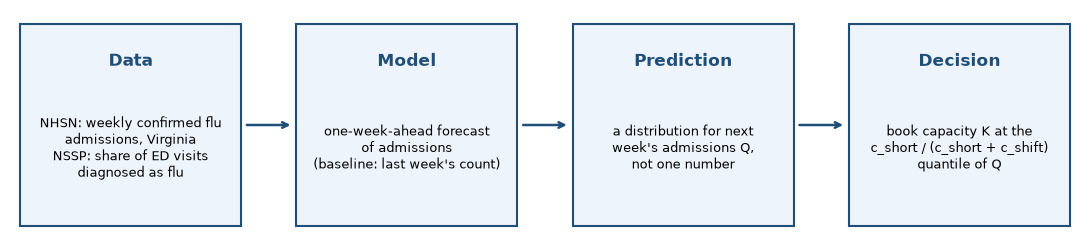

In [2]:
# Layer diagram: data -> model -> prediction -> decision. Saved as fig/layers.png.
layers = [
    ("Data", "NHSN: weekly confirmed flu\nadmissions, Virginia\nNSSP: share of ED visits\ndiagnosed as flu"),
    ("Model", "one-week-ahead forecast\nof admissions\n(baseline: last week's count)"),
    ("Prediction", "a distribution for next\nweek's admissions Q,\nnot one number"),
    ("Decision", "book capacity K at the\nc_short / (c_short + c_shift)\nquantile of Q"),
]
fig, ax = plt.subplots(figsize=(11, 2.6))
for i, (title, body) in enumerate(layers):
    x = i * 2.75
    ax.add_patch(plt.Rectangle((x, 0), 2.2, 1.5, facecolor="#eef4fb", edgecolor="#1f4e79", lw=1.5))
    ax.text(x + 1.1, 1.22, title, ha="center", va="center", fontsize=12, fontweight="bold", color="#1f4e79")
    ax.text(x + 1.1, 0.58, body, ha="center", va="center", fontsize=9)
    if i < len(layers) - 1:
        ax.annotate("", xy=(x + 2.72, 0.75), xytext=(x + 2.23, 0.75), arrowprops=dict(arrowstyle="->", lw=1.8, color="#1f4e79"))
ax.set_xlim(-0.1, 10.55); ax.set_ylim(-0.1, 1.6); ax.axis("off")
fig.tight_layout()
fig.savefig("fig/layers.png", dpi=150)
plt.show()

## Data

Two public-domain CDC extracts for Virginia, frozen on 11 November 2026 and published on this repository's `data` release. Source, terms, row counts and SHA-256 are in `data/README.md`. Download them into `data/` from the project root:

```bash
gh release download data --dir data --repo Rashed97/aii600-final-project
```

- **NHSN hospital respiratory data.** One row per state-week. `flu_adm` is confirmed influenza new admissions that week; `hosp_reporting` is how many hospitals reported that field.
- **NSSP emergency-department visits.** `ed_flu_pct` is the percentage of all ED visits diagnosed as influenza, statewide, weekly from October 2022.

The cell below is the raw data, before any model: one plot and one table.

NHSN: 326 weeks, 2020-08-08 to 2026-10-31; flu count present in 316 of them
NSSP: 214 weeks, 2022-10-01 to 2026-10-31


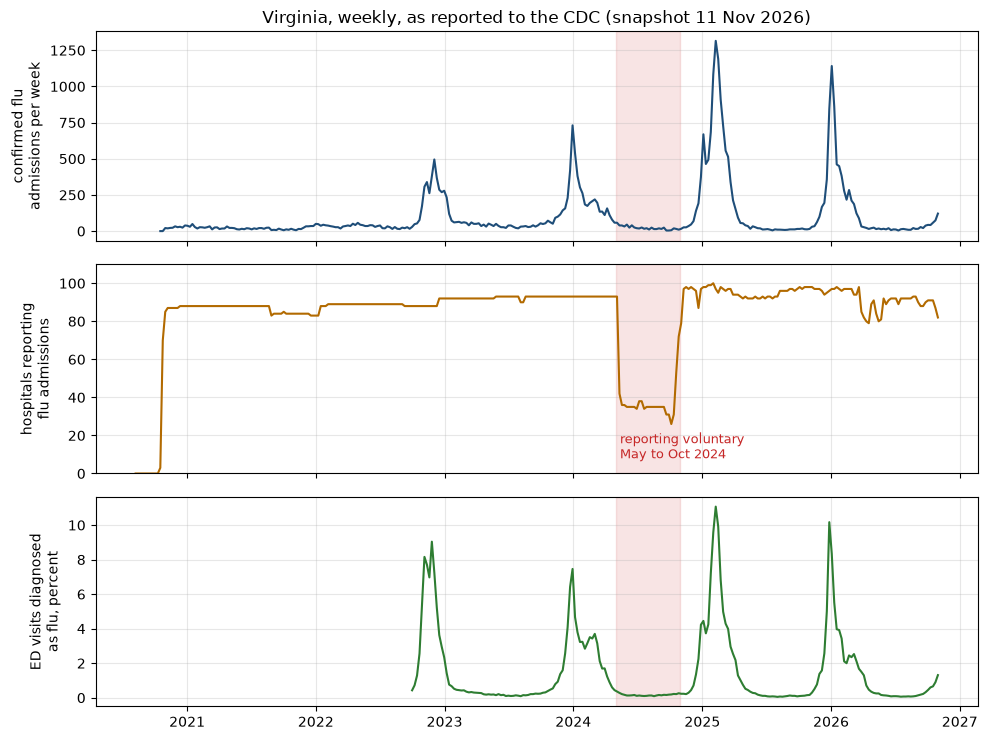

,weeks,total_adm,median_adm,peak_adm,peak_week,min_hosp,median_hosp
season,,,,,,,
2020-21,37,836.0,22.0,49.0,2021-01-16,3,88.0
2021-22,52,1434.0,30.0,57.0,2022-04-30,83,88.0
2022-23,52,5105.0,50.0,495.0,2022-12-03,88,92.0
2023-24,53,6507.0,58.0,731.0,2023-12-30,34,93.0
2024-25,52,10908.0,30.0,1315.0,2025-02-08,26,92.5
2025-26,52,6934.0,19.0,1141.0,2026-01-03,79,96.0
2026-27,18,550.0,18.5,121.0,2026-10-31,82,91.0


In [3]:
nhsn = flu.load_nhsn()
ed = flu.load_nssp("All")                      # statewide row
print(f"NHSN: {len(nhsn)} weeks, {nhsn.week_end.min().date()} to {nhsn.week_end.max().date()}; "
      f"flu count present in {nhsn.flu_adm.notna().sum()} of them")
print(f"NSSP: {len(ed)} weeks, {ed.week_end.min().date()} to {ed.week_end.max().date()}")

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(nhsn.week_end, nhsn.flu_adm, color="#1f4e79", lw=1.5)
axes[0].set_ylabel("confirmed flu\nadmissions per week")
axes[0].set_title("Virginia, weekly, as reported to the CDC (snapshot 11 Nov 2026)")
axes[1].plot(nhsn.week_end, nhsn.hosp_reporting, color="#b26a00", lw=1.5)
axes[1].set_ylabel("hospitals reporting\nflu admissions")
axes[1].set_ylim(0, 110)
axes[2].plot(ed.week_end, ed.ed_flu_pct, color="#2e7d32", lw=1.5)
axes[2].set_ylabel("ED visits diagnosed\nas flu, percent")
for ax in axes:
    ax.axvspan(flu.VOLUNTARY_START, flu.VOLUNTARY_END, color="#c62828", alpha=0.12)
    ax.grid(alpha=0.3)
axes[1].text(flu.VOLUNTARY_START, 8, " reporting voluntary\n May to Oct 2024", color="#c62828", fontsize=9)
fig.tight_layout()
fig.savefig("fig/raw.png", dpi=150)
plt.show()

# Summary by flu season (July to June). The first and last seasons are partial.
by_season = nhsn.dropna(subset=["flu_adm"]).groupby("season").agg(
    weeks=("flu_adm", "size"),
    total_adm=("flu_adm", "sum"),
    median_adm=("flu_adm", "median"),
    peak_adm=("flu_adm", "max"),
    peak_week=("flu_adm", lambda s: nhsn.loc[s.idxmax(), "week_end"].date()),
    min_hosp=("hosp_reporting", "min"),
    median_hosp=("hosp_reporting", "median"),
)
by_season

In [4]:
# Three numbers the raw plot raises, before any model.
vol = nhsn[nhsn.regime.str.startswith("voluntary")]
print(f"voluntary window: {len(vol)} weeks, hospitals reporting {vol.hosp_reporting.min()} to {vol.hosp_reporting.max()}, "
      f"median {vol.hosp_reporting.median():.0f}; outside it the median is {nhsn[~nhsn.index.isin(vol.index)].hosp_reporting.median():.0f}")
print("last four weeks (the newest week is preliminary):")
print(nhsn.tail(4)[["week_end", "flu_adm", "hosp_reporting", "pct_hosp_reporting"]].to_string(index=False))
wk = nhsn.dropna(subset=["flu_adm"]).copy()
wk["change"] = wk.flu_adm.diff()
print(f"week-to-week change in admissions: median absolute {wk.change.abs().median():.0f}, "
      f"largest rise {wk.change.max():.0f} (week ending {wk.loc[wk.change.idxmax(), 'week_end'].date()}), "
      f"largest fall {wk.change.min():.0f}")
both = nhsn.merge(ed, on="week_end").dropna(subset=["flu_adm"])
print(f"weeks with both series: {len(both)}; correlation of admissions with the same week's ED flu share: "
      f"{both.flu_adm.corr(both.ed_flu_pct):.2f}")

voluntary window: 26 weeks, hospitals reporting 26 to 93, median 35; outside it the median is 92
last four weeks (the newest week is preliminary):
  week_end  flu_adm  hosp_reporting  pct_hosp_reporting
2026-10-10     42.0              91               88.35
2026-10-17     58.0              91               88.35
2026-10-24     74.0              87               84.47
2026-10-31    121.0              82               79.61
week-to-week change in admissions: median absolute 9, largest rise 486 (week ending 2025-12-27), largest fall -401
weeks with both series: 214; correlation of admissions with the same week's ED flu share: 0.91


### What the raw data shows

All numbers below are printed by the two cells above.

- **Strongly seasonal, and the seasons differ a lot.** Six seasons with a count: the peak week ranges from 49 admissions (2020-21) to 1,315 (week ending 8 February 2025). The first two seasons, during the pandemic, have almost no flu, so they say little about what a peak looks like.
- **Last week's count is a good guess most weeks and a bad one when it matters.** The median week-to-week change is 9 admissions. The largest rise is 486 in one week (ending 27 December 2025) and the largest fall is 401. The weeks with big jumps are the weeks a staffing decision is about.
- **The reporting gap is bias, not noise, and it sits in the trough.** Outside May to October 2024 the median number of hospitals reporting is 92. Inside that window it is 35, and as low as 26, for 26 weeks. Fewer hospitals means a lower count for the same amount of flu. The window falls in the summer, when admissions are low anyway, so it distorts small numbers; it does not touch a peak.
- **The newest weeks are not final.** Over the last four weeks the hospitals reporting go 91, 91, 87, 82 while admissions go 42, 58, 74, 121. The source is labelled preliminary and is revised every Wednesday. A forecaster at the end of a week sees this incomplete count, not the final one. One snapshot cannot say how large the revisions are; a second snapshot later can.
- **The emergency-department series moves with admissions.** Over the 214 weeks that have both, the same-week correlation is 0.91. That says they move together. It does not yet say the ED share moves first, which is what would make it useful one week ahead; that is a question for the model section.

Choices these facts force, each for a later `decisions.md` entry and not made here: where the held-out period starts; whether the two pandemic seasons and the voluntary-reporting weeks enter the fit; whether counts are rescaled by hospitals reporting; and the two unit costs in the loss.

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.
